### problem 1: rolling sevens is more likely.Because rolling snake eyes have a probability of 1/6 times 1/6 which is 1/36. Rolling sevens has a probability of 6/36, which is 1/6. so rolling sevens is more likely, and the ratio of the probabilities is P(seven)/P（snake eye) = 6

### problem 2: 

In [53]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy import stats

[0.02777778 0.05555556 0.08333333 0.11111111 0.13888889 0.16666667
 0.13888889 0.11111111 0.08333333 0.05555556 0.02777778]


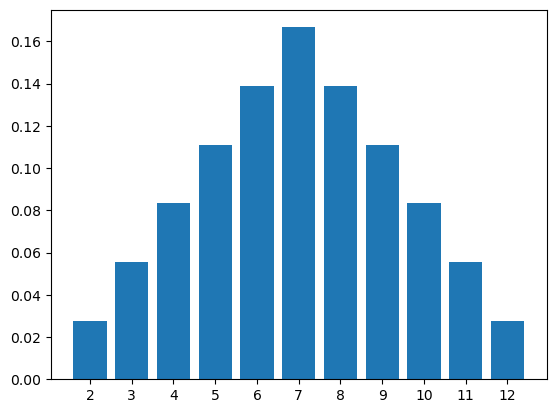

In [54]:
p=np.ones(6)/6 # one dice: six probability of 1/6   , first six means create an array of six elements, second /6 six means changes 1 to 1/6 
yaxis=np.convolve(p,p,mode='full') 
xaxis = np.arange(2,13) 
print(yaxis) 
fig, ax = plt.subplots(1, 1)
ax.bar(xaxis, yaxis) 
ax.set_xticks(xaxis)
plt.show()

### P(S)= sum (P(X=k)P(Y=s-k)), both k and s-k is between 1 and 6, rearrange and k is between max( 1, s-6 )and min(6, s-1). thus rearange again we get  P(S) is the (s-1)/36 when 2<= s<= 7 and for 8<=s<=12, P(s) = (13-s)/36. 

### problem 3: 

In [55]:
mean = np.sum(xaxis * yaxis) 
# sum of all probability times sum  
variance = np.sum((xaxis - mean)**2 * yaxis) 
# variance is the sum of all square of average value minus mean times probability
print(mean)
print(variance)
# anyaltic means is still sum of all probability times sum. we can use var(s) = E(s^2) - (E(s))^2 to compute variance 

6.999999999999998
5.833333333333333


### Problem 4: 

0.9999999999999997


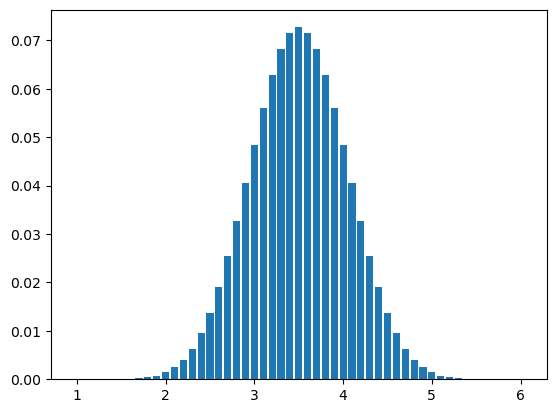

In [56]:
p = np.ones(6)/6 
yaxis10 = p.copy() 
for i in range(9):  
    yaxis10 = np. convolve(yaxis10, p, mode = 'full')
xaxis10 = np.arange(10,61)/10 
print ( np.sum(yaxis10)) 
fig, ax = plt.subplots(1,1) 
ax.bar(xaxis10,yaxis10,width = 0.08) 
plt.show()

### it is not exactly gaussian although it is close. central limit theorem state that for indepedent, identical distributed random variables. the sum after rescaling approaches a standard gaussian distgribution as number of variables increates. so although one dice has a uniform distribution, combing 10 dice after rescaling produce a roughly guassian shape. however gaussian distribution must be continous, the examples we use (rolling dice) is discrete. Thus, although it has a guassian shape, it is not exactly a gaussian distribution. 

### analytic later, just applies convolution to gaussian distribution and get for sum: average n * u , sd: sqrt(n) times sigma. for sum and then average, average is still u, sigma is  sqrt (n)/n sigma which is sigma divide by sqrt n 

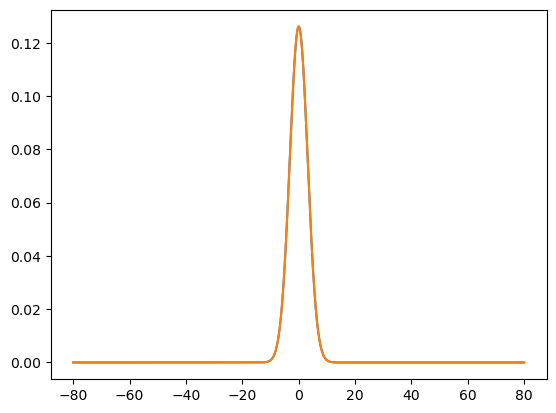

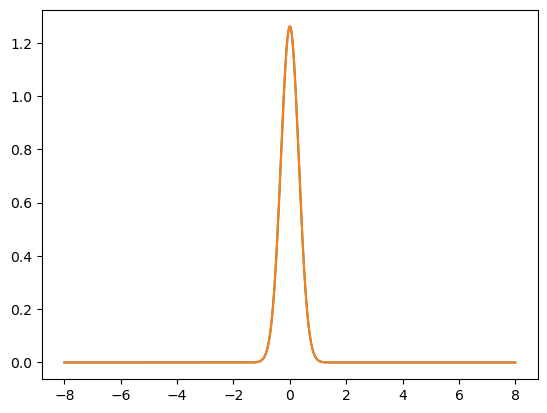

In [57]:
n =10 
x= np.linspace(-8,8,801) 
dx = x[1] - x[0] 
p=stats.norm.pdf(x,loc=0,scale=1)
p=p/np.sum(p) # convert number into proabilities over x linspace 
yaxis=p.copy()

for i in range (n-1): 
    yaxis = np.convolve(yaxis, p, mode='full') 
xsum = np.linspace(n*x[0], n*x[-1], len(yaxis)) # x[0] first value , x[-1] last value create. lens(yaxis) correspond position for yaxis
xaverage = xsum/n # rescale 

fig, ax = plt.subplots(1, 1) 
ax.plot(xsum, yaxis/dx, label="Convolution") # why divide by dx,  because we are plotting probability density unlike last time 
ax.plot(xsum, stats.norm.pdf(xsum, scale=np.sqrt(n))) 
plt.show() 

fig, ax = plt.subplots(1, 1)
ax.plot(xaverage, n*yaxis/dx) 
ax.plot(xaverage, stats.norm.pdf(xaverage, scale=1/np.sqrt(n)))
plt.show() 